# Data Sources

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kunifujiwara/VoxCity/blob/main/docs/examples/demo_data_sources.ipynb) · [All tutorials](index.md)

Which open data VoxCity uses for buildings, land cover, trees and terrain, and how to pick your own.

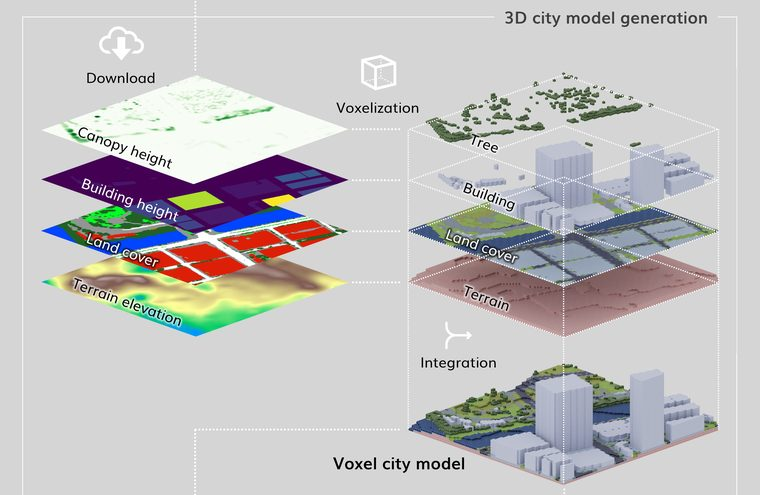

Run the cells in order: click ▶, or press **Shift + Enter**. No account needed.

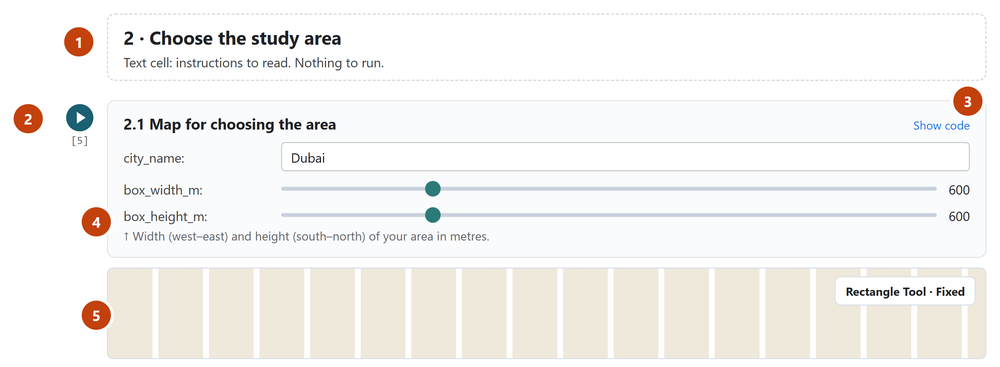

## 1 · Set-up

In [ ]:
#@title 1.1 Install VoxCity (1–2 minutes) { display-mode: "form" }
!pip install -q voxcity

## 2 · What VoxCity picks for a place
Nothing is downloaded. Without Earth Engine, `get_voxcity` swaps *EE* sources for free ones.

In [ ]:
#@title 2.1 Automatic choice for four cities { display-mode: "form" }
from voxcity.generator import auto_select_data_sources
places = {
    "Tokyo":    [(139.7620, 35.6780), (139.7620, 35.6820), (139.7670, 35.6820), (139.7670, 35.6780)],
    "New York": [(-74.015, 40.705), (-74.015, 40.709), (-74.010, 40.709), (-74.010, 40.705)],
    "London":   [(-0.130, 51.500), (-0.130, 51.504), (-0.124, 51.504), (-0.124, 51.500)],
    "Lagos":    [(3.380, 6.450), (3.380, 6.454), (3.384, 6.454), (3.384, 6.450)],
}
for name, corners in places.items():
    print(name)
    for layer, source in auto_select_data_sources(corners).items():
        print(f"   {layer:32s} {source}")

## 3 · All sources
**EE** = needs a Google Earth Engine account.

| Layer | No account | EE |
|-------|------------|----|
| Buildings | `OpenStreetMap`, `Overture`, `Microsoft Building Footprints`, `Global Building Atlas`, `EUBUCCO v0.1`, `Local file` | `Open Building 2.5D Temporal`, `England 1m DSM - DTM`, `Netherlands 0.5m DSM - DTM` |
| Land cover | `OpenStreetMap`, `ESA WorldCover`, `OpenEarthMapJapan` | `Urbanwatch`, `ESRI 10m Annual Land Cover`, `Dynamic World V1` |
| Tree height | `High Resolution 1m Global Canopy Height Maps v2`, `OpenStreetMap`, `Static` | `High Resolution 1m Global Canopy Height Maps`, `ETH Global Sentinel-2 10m Canopy Height (2020)` |
| Terrain | `FABDEM`, `COPERNICUS`, `USGS 3DEP 10m`, `GSI DEM Japan`, `Flat` | `USGS 3DEP 1m`, `England 1m DTM`, `DEM France 1m`, `DEM France 5m`, `Netherlands 0.5m DTM`, `AUSTRALIA 5M DEM`, `DeltaDTM`, `NASA` |

Coverage and resolution of each: [README data source tables](https://github.com/kunifujiwara/VoxCity#references-of-data-sources).

## 4 · Compare two sets of sources
The same Tokyo block built twice, then the inputs side by side.

In [ ]:
#@title 4.1 Build with set A and set B (2–5 minutes) { display-mode: "form" }
#@markdown **Set A**
a_buildings = 'OpenStreetMap' #@param ['OpenStreetMap', 'Overture', 'Global Building Atlas']
a_land_cover = 'OpenStreetMap' #@param ['OpenStreetMap', 'ESA WorldCover', 'OpenEarthMapJapan']
a_trees = 'Static' #@param ['High Resolution 1m Global Canopy Height Maps v2', 'OpenStreetMap', 'Static']
#@markdown **Set B**
b_buildings = 'Overture' #@param ['OpenStreetMap', 'Overture', 'Global Building Atlas']
b_land_cover = 'ESA WorldCover' #@param ['OpenStreetMap', 'ESA WorldCover', 'OpenEarthMapJapan']
b_trees = 'High Resolution 1m Global Canopy Height Maps v2' #@param ['High Resolution 1m Global Canopy Height Maps v2', 'OpenStreetMap', 'Static']
from voxcity.generator import get_voxcity
area = places["Tokyo"]
city_a = get_voxcity(area, 5, building_source=a_buildings, land_cover_source=a_land_cover,
                     canopy_height_source=a_trees, dem_source="GSI DEM Japan", output_dir="output/sources/a")
city_b = get_voxcity(area, 5, building_source=b_buildings, land_cover_source=b_land_cover,
                     canopy_height_source=b_trees, dem_source="GSI DEM Japan", output_dir="output/sources/b")

In [ ]:
#@title 4.2 Inputs side by side { display-mode: "form" }
import matplotlib.pyplot as plt
layers = [("Building height (m)", lambda c: c.buildings.heights, "viridis"),
          ("Land cover class", lambda c: c.land_cover.classes, "tab20"),
          ("Tree height (m)", lambda c: c.tree_canopy.top, "Greens")]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, (label, c) in enumerate([("Set A", city_a), ("Set B", city_b)]):
    for col, (title, get, cmap) in enumerate(layers):
        ax = axes[row, col]
        im = ax.imshow(get(c), origin="lower", cmap=cmap)
        ax.set_title(f"{label}: {title}"); ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout(); plt.show()

## 5 · Your own buildings
Any GeoPackage of footprints with a `height` column (m). Here we save set A's buildings and read them back.

In [ ]:
#@title 5.1 Build from a building file { display-mode: "form" }
my_file = "output/sources/my_buildings.gpkg"
city_a.extras["building_gdf"][["id", "height", "geometry"]].to_file(my_file, driver="GPKG")
city_own = get_voxcity(area, 5, building_source="Local file", building_path=my_file,
                       land_cover_source="OpenStreetMap", canopy_height_source="Static", dem_source="Flat",
                       output_dir="output/sources/own")
print("Buildings read from the file:", len(city_own.extras["building_gdf"]))

## 6 · Land cover classes
Every source is translated into the same 14 classes.

In [ ]:
#@title 6.1 The 14 classes { display-mode: "form" }
from voxcity.utils.lc import get_land_cover_classes
for number, name in enumerate(dict.fromkeys(get_land_cover_classes("OpenStreetMap").values()), start=1):
    print(number, name)

## 7 · Earth Engine (optional)
Only for *EE* sources. Set up a project with the [official guide](https://developers.google.com/earth-engine/cloud/earthengine_cloud_project_setup), then run:

In [ ]:
#@title (Optional) 7.1 Sign in to Earth Engine { display-mode: "form" }
project_id = "your-project-id"  #@param {type:"string"}
if project_id == "your-project-id":
    print("Type your Earth Engine project ID in the form, then run this cell again.")
else:
    import ee
    ee.Authenticate()
    ee.Initialize(project=project_id)
    print("Signed in. Sources marked EE can now be used.")

## Next steps
[Complete demo](demo_basic.ipynb) · [All tutorials](index.md) · [Questions](https://github.com/kunifujiwara/VoxCity/discussions)